<a href="https://colab.research.google.com/github/TreesaAbraham/svd-image-compression-MATH344L/blob/main/notebook/03_images_compress_SVD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
#Milestone 3

In [12]:
import os
import subprocess
import sys

USER = "TreesaAbraham"
REPO = "svd-image-compression-MATH344L"

if os.path.exists(REPO):
    subprocess.run(["git", "-C", REPO, "pull"], check=True)
else:
    subprocess.run(
        ["git", "clone", f"https://github.com/{USER}/{REPO}.git", REPO],
        check=True)

sys.path.insert(0, f"{REPO}/src")
from compress import rank_k_approx

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

A = data.camera().astype(float)
m, n = A.shape
T = data.text().astype(float)
print("Camera:", A.shape, "Text:", T.shape)

Camera: (512, 512) Text: (172, 448)


In [14]:
def storage(m, n, k):
#Number of values needed to store a rank-k approximation.
  return k * (m + n + 1)
def compression_ratio(m, n, k):
#Original number of values divided by compressed number of values.
  return (m * n) / storage(m, n, k)
print("Original camera values:", m * n)
for k in [1, 10, 50, 100, 255, 256]:
  print(f"k={k:3d} stored={storage(m, n, k):6d}"
f"ratio={compression_ratio(m, n, k):.2f}")

Original camera values: 262144
k=  1 stored=  1025ratio=255.75
k= 10 stored= 10250ratio=25.58
k= 50 stored= 51250ratio=5.12
k=100 stored=102500ratio=2.56
k=255 stored=261375ratio=1.00
k=256 stored=262400ratio=1.00


In [15]:
#part c

def rel_error(A, B):
  #relative Frobenius error when B approximates A
  return np.linalg.norm(A-B) / np.linalg.norm(A)

for k in [1, 5, 20, 50, 100]:
  Ak = rank_k_approx(A, k)
  print(f"k={k:3d} relative error={rel_error(A, Ak):.4f}")

k=  1 relative error=0.3604
k=  5 relative error=0.1720
k= 20 relative error=0.1012
k= 50 relative error=0.0636
k=100 relative error=0.0393


In [16]:
#part D

U, s, Vt = np.linalg.svd(A, full_matrices = False)

def predicted_error(s, k):
  #relative rank-k error computed from the singular values
  return np.sqrt(np.sum(s[k:]**2) / np.sum(s**2))

for k in [1, 5, 20, 50, 100]:
  actual = rel_error(A, rank_k_approx(A, k))
  predicted = predicted_error(s, k)
  print(f"k={k:3d} actual={actual:.6f} predicted={predicted:.6f}")



k=  1 actual=0.360449 predicted=0.360449
k=  5 actual=0.172014 predicted=0.172014
k= 20 actual=0.101208 predicted=0.101208
k= 50 actual=0.063565 predicted=0.063565
k=100 actual=0.039329 predicted=0.039329


In [17]:
#part e

ks = np.arange(1, len(s) + 1)
errors = np.array([predicted_error(s,k) for k in ks])
for target in [0.10, 0.05, 0.02, 0.01]:
  k = ks[errors <= target][0]
  ratio = compression_ratio(m, n, k)
  print(f"k={k}, ratio={ratio:.2f}")

k=21, ratio=12.18
k=73, ratio=3.50
k=186, ratio=1.38
k=263, ratio=0.97


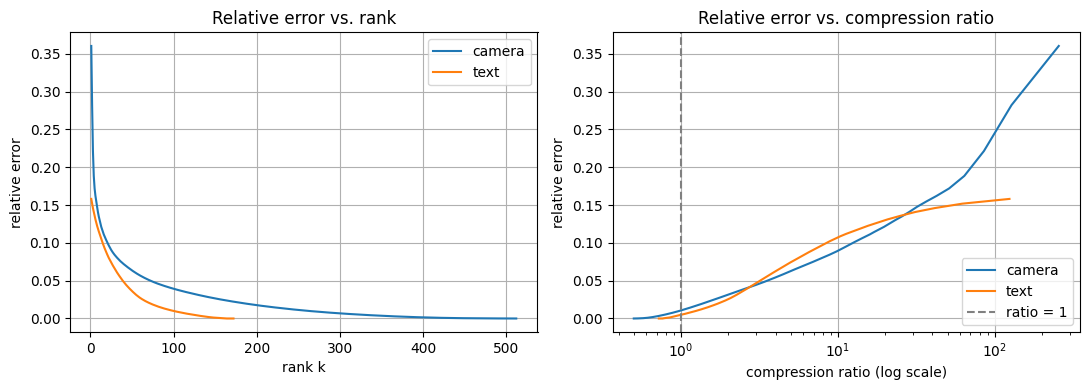

In [21]:
#part F

images = {"camera": A, "text": T}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
for name, M in images.items():
  m_img, n_img = M.shape
  s_img = np.linalg.svd(M, compute_uv=False)
  ranks = np.arange(1, len(s_img) + 1)
  errs = [predicted_error(s_img, k) for k in ranks]
  ratios = [compression_ratio(m_img, n_img, k) for k in ranks]
  ax1.plot(ranks, errs, label=name)
  ax2.semilogx(ratios, errs, label=name)
ax1.set_title("Relative error vs. rank")
ax1.set_xlabel("rank k")
ax1.set_ylabel("relative error")
ax2.axvline(1, color="gray", linestyle="--", label="ratio = 1")
ax2.set_title("Relative error vs. compression ratio")
ax2.set_xlabel("compression ratio (log scale)")
ax2.set_ylabel("relative error")
for ax in (ax1, ax2):
  ax.grid()
  ax.legend()
plt.tight_layout()
plt.savefig("error_vs_ratio.png", dpi=150)
plt.show()

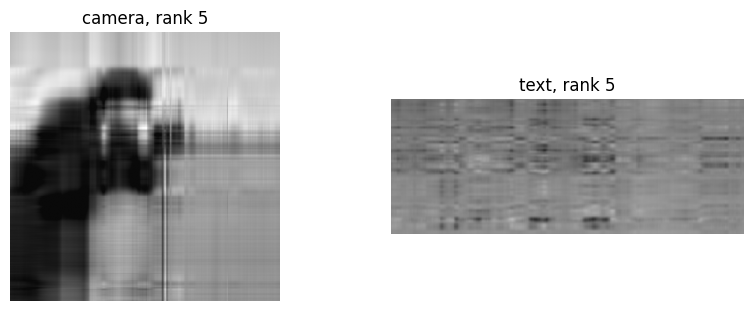

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, (name, M) in zip(axes, images.items()):
  Mk = np.clip(rank_k_approx(M, 5), 9, 255)
  ax.imshow(Mk, cmap="gray", vmin=0, vmax=255)
  ax.set_title(f"{name}, rank 5")
  ax.axis("off")
plt.show()

In [ ]:
#part G